# Phase 3 - Analysis: new construction and collision injuries by ZIP code

**Author:** Ahmed Sanad | **Input:** `data/zip_year.csv` (Issa's integrated ZIP x year table) | **Scope:** 2022-01-01 to 2026-10-31

Two research questions, each with one chart. Everything below describes **association** between two datasets; nothing here shows that construction causes, or is caused by, collisions or injuries.

### How to run
1. Create a venv and `pip install -r requirements.txt` (see the README).
2. Produce `data/zip_year.csv` by running the Phase 2 notebooks in order (the missing-file error below names the one that writes it).
3. In VS Code choose the venv kernel and **Restart Kernel and Run All**.

**Datasets used (NYC Open Data):** [DOB NOW: Build Job Application Filings (w9ak-ipjd)](https://data.cityofnewyork.us/d/w9ak-ipjd) and [Motor Vehicle Collisions, Crashes (h9gi-nx95)](https://data.cityofnewyork.us/d/h9gi-nx95).

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

DATA_PATH = Path("data") / "zip_year.csv"
COLLISIONS_STEP2 = Path("data") / "collisions_step2.csv.gz"     # only used for the missing-ZIP context cell
RQ_DIR = Path("assets") / "rq"      # charts for the website
RQ_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
RESULTS = {}                      # numbers that the findings text quotes; printed at the end

## 1. Load and check the integrated table

The file is written by `phase2_data_integration_issa.ipynb`. If it is missing we stop with a clear message instead of guessing.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"{DATA_PATH} not found. Run phase2_data_integration_issa.ipynb first "
        "(it needs the housing and collisions ZIP x year files from the other Phase 2 notebooks).")

zy = pd.read_csv(DATA_PATH, dtype={"zip_code": str})

# the shared contract: 5-digit string ZIPs, integer years 2022-2026, no NaN in the counts used here
assert zy["zip_code"].str.fullmatch(r"\d{5}").all(), "zip_code must be 5-digit strings"
assert pd.api.types.is_integer_dtype(zy["year"]) and zy["year"].between(2022, 2026).all()
COUNTS = ["housing_job_count", "new_building_count", "collision_count", "persons_injured",
          "pedestrians_injured", "cyclist_injured", "motorist_injured"]
assert zy[COUNTS].notna().all().all() and (zy[COUNTS] >= 0).all().all()
assert not zy.duplicated(["zip_code", "year"]).any(), "one row per zip_code x year expected"

print("rows x columns:", zy.shape, "| ZIP codes:", zy["zip_code"].nunique(), "| years:", sorted(zy["year"].unique()))
print("extra columns used below:", [c for c in ["low_data_flag", "top_contributing_factor", "is_partial_year"] if c in zy])

rows x columns: (1123, 25) | ZIP codes: 232 | years: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
extra columns used below: ['low_data_flag', 'top_contributing_factor', 'is_partial_year']


## 2. Analysis table: full years only, low-data ZIP-years left out

**What we do and why**
- **Full years only (2022-2025).** 2026 covers January to October only, so its counts are not comparable with a full year. *Alternative rejected:* scaling 2026 by 12/10, which invents data and assumes crashes are spread evenly over the year.
- **Leave out `low_data_flag` ZIP-years** (fewer than 5 collisions *and* fewer than 5 housing jobs, flagged by Issa). Their rates are mostly noise. They are listed below instead of silently dropped. *Alternative rejected:* keeping them, because a ZIP-year with 1 crash can show an injury rate of 0% or 100%.
- **One row per ZIP**: counts are summed over the remaining full years of that ZIP.
- **Minimum of 100 collisions per ZIP over those years.** Our outcome is a rate (injuries per 100 collisions); with very few collisions a rate is unstable. *Alternative rejected:* weighting or smoothing the rates, which adds modelling choices we cannot justify in this milestone.

In [3]:
full = zy[zy["year"] <= 2025]
flagged = full[full["low_data_flag"]]
kept = full[~full["low_data_flag"]]
print(f"full-year ZIP-years: {len(full)} | low_data_flag ZIP-years left out: {len(flagged)} | kept: {len(kept)}")
print("ZIPs that lose ALL their years to the flag:", sorted(set(flagged['zip_code']) - set(kept['zip_code'])))

zips = (kept.groupby("zip_code")
            .agg(borough=("borough", "first"),
                 new_buildings=("new_building_count", "sum"),
                 collisions=("collision_count", "sum"),
                 ped_injured=("pedestrians_injured", "sum"),
                 cyc_injured=("cyclist_injured", "sum"),
                 years=("year", "nunique"))
            .reset_index())
n_zip_before = len(zips)
MIN_COLLISIONS = 100
zips = zips[zips["collisions"] >= MIN_COLLISIONS].copy()
zips["pc_injured"] = zips["ped_injured"] + zips["cyc_injured"]
for col, name in [("pc_injured", "pc_rate"), ("ped_injured", "ped_rate"), ("cyc_injured", "cyc_rate")]:
    zips[name] = zips[col] / zips["collisions"] * 100       # injuries per 100 collisions
print(f"ZIPs with at least one kept year: {n_zip_before} | with >= {MIN_COLLISIONS} collisions: {len(zips)}")
RESULTS.update(rows_full=len(full), rows_flagged=len(flagged), rows_kept=len(kept),
               zips_before=n_zip_before, zips_analysed=len(zips), min_collisions=MIN_COLLISIONS)
zips.describe().round(2)

full-year ZIP-years: 898 | low_data_flag ZIP-years left out: 39 | kept: 859
ZIPs that lose ALL their years to the flag: ['10045', '10048', '10111', '10152', '10154', '10162', '10179', '10279', '11371', '11695']
ZIPs with at least one kept year: 220 | with >= 100 collisions: 172


,new_buildings,collisions,ped_injured,cyc_injured,years,pc_injured,pc_rate,ped_rate,cyc_rate
count,172.00,172.00,172.00,172.00,172.0,172.00,172.00,172.00,172.00
mean,38.86,1554.55,172.21,92.00,4.0,264.21,16.36,10.68,5.67
std,53.61,966.76,116.53,78.35,0.0,179.52,5.68,2.88,3.79
min,0.00,106.00,3.00,1.00,4.0,4.00,3.03,2.27,0.75
25%,9.75,851.00,85.00,27.25,4.0,121.25,12.03,8.58,2.81
50%,26.00,1381.00,142.50,70.00,4.0,229.50,15.79,10.30,4.57
75%,47.00,2109.00,253.00,133.25,4.0,404.75,19.81,12.66,8.16
max,430.00,6472.00,633.00,317.00,4.0,827.00,31.62,18.94,19.14


### Context: crashes without a ZIP are not in this table
About 28% of all crashes have no ZIP code and cannot be placed in a ZIP x year cell (`phase1_collisions_eda_cleaning_ahmed.ipynb`, section 4.5). The share is higher in the early years, so every ZIP-level count here is an undercount, and the undercount is larger for 2022-2023. The cell below recomputes the shares when the Stage 2 file is available.

In [4]:
if COLLISIONS_STEP2.exists():
    cs = pd.read_csv(COLLISIONS_STEP2, usecols=["zip_code", "year"], dtype={"zip_code": str})
    miss = cs["zip_code"].isna()
    by_year = miss.groupby(cs["year"]).mean().mul(100).round(1)
    print(f"crashes without a ZIP: {miss.sum():,} of {len(cs):,} ({miss.mean():.1%})")
    print("share without ZIP by year (%):", by_year.to_dict())
    RESULTS.update(miss_share=round(100 * miss.mean(), 1), miss_2022=float(by_year[2022]), miss_2025=float(by_year[2025]))
else:
    print("data/collisions_step2.csv.gz not found: run phase1_collisions_eda_cleaning_ahmed.ipynb to see the exact shares.")

data/collisions_step2.csv.gz not found: run phase1_collisions_eda_cleaning_ahmed.ipynb to see the exact shares.


## 3. Research question 1: are ZIPs with more new buildings also the ones with more pedestrian and cyclist injuries?

**Method.**
1. For every analysed ZIP, add up new-building jobs started over the kept full years (2022-2025). `new_building_count` counts unique jobs started with `job_type` New Building, not filings.
2. Rank the ZIPs by that number. **Top quartile** = ZIPs at or above the 75th percentile; **bottom quartile** = ZIPs at or below the 25th percentile.
3. Compare **injuries per 100 collisions**, not raw injury counts. Raw counts grow with the size of a ZIP (more roads, more people, more crashes), so they would make busy ZIPs look dangerous whatever the construction. Dividing by collisions asks a different question: *when a crash happens, how often are pedestrians or cyclists hurt?*
4. Pooled rate per group = total injuries / total collisions x 100. The error bars are 95% bootstrap intervals (resampling ZIPs, 2,000 draws, seed 42).
5. Also report the **Spearman rank correlation** across all analysed ZIPs with a two-sided **permutation p-value** (10,000 shuffles). Spearman uses ranks, so a few huge ZIPs cannot dominate it.

**Why this chart.** Grouped bars put the two quartile groups side by side for each injury type, so the reader compares the groups directly; the error bars show how uncertain each bar is.

In [5]:
rng = np.random.default_rng(SEED)

q25, q75 = zips["new_buildings"].quantile([0.25, 0.75])
zips["group"] = np.where(zips["new_buildings"] >= q75, "Top quartile (most new buildings)",
                 np.where(zips["new_buildings"] <= q25, "Bottom quartile (fewest new buildings)", "Middle"))
TOP, BOTTOM = "Top quartile (most new buildings)", "Bottom quartile (fewest new buildings)"
print(f"quartile cut points (new-building jobs per ZIP, 2022-2025): 25th = {q25:g}, 75th = {q75:g}")
print(zips["group"].value_counts().to_string())

def pooled_rate(frame, injuries_col):
    return frame[injuries_col].sum() / frame["collisions"].sum() * 100

def bootstrap_ci(frame, injuries_col, draws=2000):
    idx = np.arange(len(frame))
    values = [pooled_rate(frame.iloc[rng.choice(idx, size=len(idx), replace=True)], injuries_col) for _ in range(draws)]
    return np.percentile(values, [2.5, 97.5])

rows = []
for group in [BOTTOM, TOP]:
    part = zips[zips["group"] == group]
    for label, col in [("Pedestrians", "ped_injured"), ("Cyclists", "cyc_injured"), ("Pedestrians + cyclists", "pc_injured")]:
        low, high = bootstrap_ci(part, col)
        rows.append({"group": group, "injury type": label, "zips": len(part), "collisions": int(part["collisions"].sum()),
                     "injured": int(part[col].sum()), "per 100 collisions": pooled_rate(part, col), "ci_low": low, "ci_high": high})
q1 = pd.DataFrame(rows)
q1.round(2)

quartile cut points (new-building jobs per ZIP, 2022-2025): 25th = 9.75, 75th = 47
group
Middle                                    85
Top quartile (most new buildings)         44
Bottom quartile (fewest new buildings)    43


,group,injury type,zips,collisions,injured,per 100 collisions,ci_low,ci_high
0,Bottom quartile (fewest new buildings),Pedestrians,43,40684,4977,12.23,11.33,13.10
1,Bottom quartile (fewest new buildings),Cyclists,43,40684,3744,9.20,7.67,10.76
2,Bottom quartile (fewest new buildings),Pedestrians + cyclists,43,40684,8721,21.44,19.22,23.51
3,Top quartile (most new buildings),Pedestrians,44,89455,9644,10.78,9.95,11.64
4,Top quartile (most new buildings),Cyclists,44,89455,4219,4.72,3.82,5.66
5,Top quartile (most new buildings),Pedestrians + cyclists,44,89455,13863,15.50,14.30,16.71


In [6]:
# Spearman rank correlation with a permutation p-value (no extra dependency needed)
def spearman_perm(x, y, permutations=10_000):
    rx, ry = x.rank().to_numpy(), y.rank().to_numpy()
    rho = np.corrcoef(rx, ry)[0, 1]
    null = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(permutations)])
    return rho, (np.sum(np.abs(null) >= abs(rho)) + 1) / (permutations + 1)

rho_rate, p_rate = spearman_perm(zips["new_buildings"], zips["pc_rate"])
rho_raw, p_raw = spearman_perm(zips["new_buildings"], zips["pc_injured"])
rho_size, p_size = spearman_perm(zips["new_buildings"], zips["collisions"])
print(f"new buildings vs pedestrian+cyclist injuries PER 100 COLLISIONS : rho = {rho_rate:.3f}, p = {p_rate:.4f}  (n = {len(zips)} ZIPs)")
print(f"new buildings vs RAW pedestrian+cyclist injuries                : rho = {rho_raw:.3f}, p = {p_raw:.4f}")
print(f"new buildings vs collisions (ZIP size / activity)               : rho = {rho_size:.3f}, p = {p_size:.4f}")

by_borough = zips.groupby("borough").apply(lambda f: pd.Series({"zips": len(f), "pc per 100 collisions": pooled_rate(f, "pc_injured")}), include_groups=False)
print()
print(by_borough.round(2).to_string())

new buildings vs pedestrian+cyclist injuries PER 100 COLLISIONS : rho = -0.325, p = 0.0001  (n = 172 ZIPs)
new buildings vs RAW pedestrian+cyclist injuries                : rho = 0.200, p = 0.0084
new buildings vs collisions (ZIP size / activity)               : rho = 0.427, p = 0.0001

               zips  pc per 100 collisions
borough                                   
Bronx          25.0                  15.46
Brooklyn       38.0                  17.10
Manhattan      40.0                  23.22
Queens         59.0                  14.64
Staten Island  10.0                  10.15


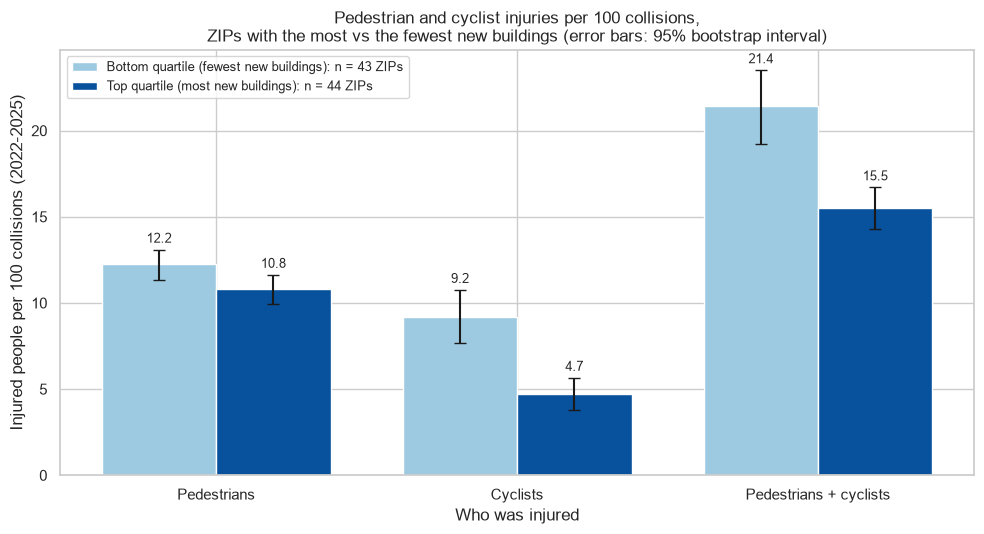

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))
order = ["Pedestrians", "Cyclists", "Pedestrians + cyclists"]
width = 0.38
colors = {BOTTOM: "#9ecae1", TOP: "#08519c"}
for offset, group in zip([-width / 2, width / 2], [BOTTOM, TOP]):
    part = q1[q1["group"] == group].set_index("injury type").loc[order]
    x = np.arange(len(order)) + offset
    err = [part["per 100 collisions"] - part["ci_low"], part["ci_high"] - part["per 100 collisions"]]
    ax.bar(x, part["per 100 collisions"], width, yerr=err, capsize=4, color=colors[group],
           label=f"{group}: n = {int(part['zips'].iloc[0])} ZIPs")
    for xi, value, top_edge in zip(x, part["per 100 collisions"], part["ci_high"]):
        ax.text(xi, top_edge + 0.4, f"{value:.1f}", ha="center", fontsize=9)
ax.set_xticks(np.arange(len(order))); ax.set_xticklabels(order)
ax.set_xlabel("Who was injured")
ax.set_ylabel("Injured people per 100 collisions (2022-2025)")
ax.set_title("Pedestrian and cyclist injuries per 100 collisions,\nZIPs with the most vs the fewest new buildings (error bars: 95% bootstrap interval)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
fig.savefig(RQ_DIR / "ahmed_q1.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
top = q1[(q1["group"] == TOP)].set_index("injury type")
bot = q1[(q1["group"] == BOTTOM)].set_index("injury type")
RESULTS.update(q25=float(q25), q75=float(q75), n_top=int(top["zips"].iloc[0]), n_bottom=int(bot["zips"].iloc[0]),
               rho_rate=round(float(rho_rate), 3), p_rate=round(float(p_rate), 4),
               rho_raw=round(float(rho_raw), 3), rho_size=round(float(rho_size), 3),
               pc_top=round(float(top.loc["Pedestrians + cyclists", "per 100 collisions"]), 1),
               pc_bot=round(float(bot.loc["Pedestrians + cyclists", "per 100 collisions"]), 1),
               pc_top_lo=round(float(top.loc["Pedestrians + cyclists", "ci_low"]), 1), pc_top_hi=round(float(top.loc["Pedestrians + cyclists", "ci_high"]), 1),
               pc_bot_lo=round(float(bot.loc["Pedestrians + cyclists", "ci_low"]), 1), pc_bot_hi=round(float(bot.loc["Pedestrians + cyclists", "ci_high"]), 1),
               ped_top=round(float(top.loc["Pedestrians", "per 100 collisions"]), 1), ped_bot=round(float(bot.loc["Pedestrians", "per 100 collisions"]), 1),
               cyc_top=round(float(top.loc["Cyclists", "per 100 collisions"]), 1), cyc_bot=round(float(bot.loc["Cyclists", "per 100 collisions"]), 1))
print({k: RESULTS[k] for k in ["q25", "q75", "n_top", "n_bottom", "pc_top", "pc_bot", "ped_top", "ped_bot", "cyc_top", "cyc_bot", "rho_rate", "p_rate", "rho_raw", "rho_size"]})

{'q25': 9.75, 'q75': 47.0, 'n_top': 44, 'n_bottom': 43, 'pc_top': 15.5, 'pc_bot': 21.4, 'ped_top': 10.8, 'ped_bot': 12.2, 'cyc_top': 4.7, 'cyc_bot': 9.2, 'rho_rate': -0.325, 'p_rate': 0.0001, 'rho_raw': 0.2, 'rho_size': 0.427}


**Finding (Q1).** Across the 172 analysed ZIPs, the 44 ZIPs in the top quartile for new buildings (at least 47 new-building jobs in 2022-2025) had 15.5 pedestrian and cyclist injuries per 100 collisions (95% interval 14.3 to 16.7). The 43 ZIPs in the bottom quartile (at most 9.75 jobs) had 21.4 per 100 collisions (95% interval 19.2 to 23.5). Across all analysed ZIPs the Spearman correlation between new buildings and this rate is -0.325, i.e. *negative*: ZIPs with more new buildings have a lower rate (permutation p = 0.0001, which is the smallest value 10,000 shuffles can give, so p < 0.001). By contrast, new buildings are strongly correlated with the *number of collisions* in a ZIP (Spearman 0.427) and with *raw* pedestrian and cyclist injuries (0.200), which is exactly why raw counts would be misleading.

**Limitation and confounder (Q1).** *Busy ZIPs have both more building and more traffic*, so a ZIP with many new buildings is also a ZIP with many people, cars and crashes. Dividing by collisions removes the size effect but not other differences between ZIPs (street layout, speed limits, how many people walk or cycle, borough). There is no traffic-volume or pedestrian-count data, so we cannot compare exposure. Rates in small ZIPs are noisy even with the 100-collision minimum, which is why the intervals are wide. About 28% of crashes have no ZIP and are excluded (more in 2022-2023), the `low_data_flag` ZIP-years were left out, and 2026 is not used because it is a partial year. This is an association between two ZIP-level summaries; it does not show that new construction changes who gets hurt.

## 4. Research question 2: do ZIPs with the most new construction have a different contributing-factor profile?

**Method.**
1. Use `top_contributing_factor` from the integrated table: for each ZIP-year it is the most common contributing factor among that ZIP-year's crashes, ignoring the uninformative values "Unspecified" and "Does Not Apply" (Yassin's aggregation). ZIP-years with no informative factor are missing and are left out.
2. Use the **same top-quartile and bottom-quartile ZIP groups as Q1**, so the two questions describe the same ZIPs.
3. For each group, count how many ZIP-years have each top factor and convert to **shares of that group's ZIP-years**. The five most common factors would be shown and any others grouped as "Other"; in the real table only four different top factors occur, so all four are shown and there is no "Other" bar.
4. Compare the two profiles with the total difference between the two share vectors (half the sum of absolute differences, in percentage points) and a **permutation test that shuffles the high/low label across ZIPs** (not across ZIP-years, because the years of one ZIP belong together), 5,000 shuffles.

**Why this chart.** A 100% stacked bar shows composition: each bar adds to 100%, so groups of different sizes are comparable, and the reader sees directly whether the mix of factors differs between the two groups.

In [9]:
if "top_contributing_factor" not in kept.columns:
    raise KeyError("top_contributing_factor is not in zip_year.csv; use the injuries-per-100-collisions-by-borough fallback instead.")

groups = zips.loc[zips["group"].isin([TOP, BOTTOM]), ["zip_code", "group"]]
py = kept.merge(groups, on="zip_code", how="inner")
print("ZIP-years in the two groups:", len(py), "| without an informative top factor (left out):", int(py["top_contributing_factor"].isna().sum()))
py = py.dropna(subset=["top_contributing_factor"])

top5 = py["top_contributing_factor"].value_counts().head(5).index.tolist()
py["factor_shown"] = py["top_contributing_factor"].where(py["top_contributing_factor"].isin(top5), "Other")
counts = pd.crosstab(py["group"], py["factor_shown"]).loc[[TOP, BOTTOM]]
counts = counts[top5 + (["Other"] if "Other" in counts.columns else [])]
shares = counts.div(counts.sum(axis=1), axis=0) * 100
print("ZIP-years per group:", counts.sum(axis=1).to_dict())
print(shares.round(1).T.to_string())

ZIP-years in the two groups: 348 | without an informative top factor (left out): 0
ZIP-years per group: {'Top quartile (most new buildings)': 176, 'Bottom quartile (fewest new buildings)': 172}
group                           Top quartile (most new buildings)  Bottom quartile (fewest new buildings)
factor_shown                                                                                             
Driver Inattention/Distraction                               89.8                                    94.8
Failure to Yield Right-of-Way                                 9.7                                     2.9
Passing or Lane Usage Improper                                0.6                                     1.7
Other Vehicular                                               0.0                                     0.6


difference between the two factor profiles: 6.8 percentage points (permutation p = 0.2032)


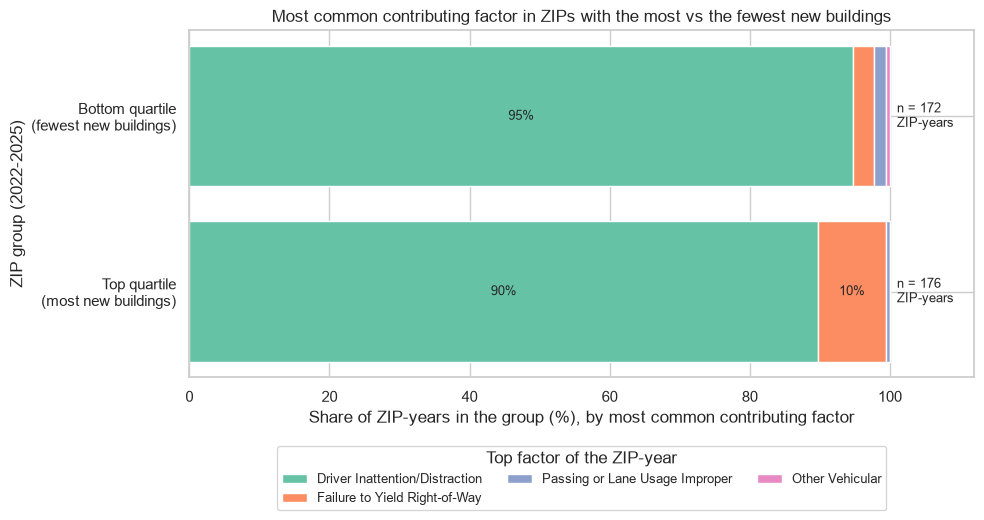

In [10]:
def tv_distance(frame):
    c = pd.crosstab(frame["group"], frame["factor_shown"])
    s = c.div(c.sum(axis=1), axis=0)
    return 50 * np.abs(s.loc[TOP] - s.loc[BOTTOM]).sum()          # in percentage points

observed = tv_distance(py)
zip_group = groups.set_index("zip_code")["group"]
null = []
for _ in range(5000):
    shuffled = pd.Series(rng.permutation(zip_group.to_numpy()), index=zip_group.index)
    null.append(tv_distance(py.assign(group=py["zip_code"].map(shuffled))))
p_profile = (np.sum(np.array(null) >= observed) + 1) / (len(null) + 1)
print(f"difference between the two factor profiles: {observed:.1f} percentage points (permutation p = {p_profile:.4f})")

fig, ax = plt.subplots(figsize=(10, 5.5))
palette = sns.color_palette("Set2", n_colors=len(shares.columns))
left = np.zeros(len(shares))
labels = ["Top quartile\n(most new buildings)", "Bottom quartile\n(fewest new buildings)"]
for color, factor in zip(palette, shares.columns):
    ax.barh(labels, shares[factor], left=left, color=color, label=factor, edgecolor="white")
    for y, (l, v) in enumerate(zip(left, shares[factor])):
        if v >= 4:
            ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=9)
    left += shares[factor].to_numpy()
for y, group in enumerate([TOP, BOTTOM]):
    ax.text(101, y, f"n = {int(counts.loc[group].sum())}\nZIP-years", va="center", fontsize=9)
ax.set_xlim(0, 112)
ax.set_xlabel("Share of ZIP-years in the group (%), by most common contributing factor")
ax.set_ylabel("ZIP group (2022-2025)")
ax.set_title("Most common contributing factor in ZIPs with the most vs the fewest new buildings")
ax.legend(title="Top factor of the ZIP-year", bbox_to_anchor=(0.5, -0.18), loc="upper center", ncol=3, fontsize=9)
plt.tight_layout()
fig.savefig(RQ_DIR / "ahmed_q2.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
main = top5[0]
RESULTS.update(q2_n_top=int(counts.loc[TOP].sum()), q2_n_bottom=int(counts.loc[BOTTOM].sum()), q2_main=main,
               q2_main_top=round(float(shares.loc[TOP, main]), 1), q2_main_bottom=round(float(shares.loc[BOTTOM, main]), 1),
               q2_tvd=round(float(observed), 1), q2_p=round(float(p_profile), 4),
               q2_second=top5[1], q2_second_top=round(float(shares.loc[TOP, top5[1]]), 1), q2_second_bottom=round(float(shares.loc[BOTTOM, top5[1]]), 1))
print({k: RESULTS[k] for k in ["q2_n_top", "q2_n_bottom", "q2_main", "q2_main_top", "q2_main_bottom", "q2_second", "q2_second_top", "q2_second_bottom", "q2_tvd", "q2_p"]})

{'q2_n_top': 176, 'q2_n_bottom': 172, 'q2_main': 'Driver Inattention/Distraction', 'q2_main_top': 89.8, 'q2_main_bottom': 94.8, 'q2_second': 'Failure to Yield Right-of-Way', 'q2_second_top': 9.7, 'q2_second_bottom': 2.9, 'q2_tvd': 6.8, 'q2_p': 0.2032}


**Finding (Q2).** The contributing-factor profile of the two groups is similar. "Driver Inattention/Distraction" is the most common top factor in 89.8% of ZIP-years in the top-quartile ZIPs (176 ZIP-years) and in 94.8% in the bottom-quartile ZIPs (172 ZIP-years). The second most common, "Failure to Yield Right-of-Way", has shares of 9.7% and 2.9%. The two profiles differ by 6.8 percentage points in total, with a permutation p-value of 0.2032.

**Limitation and confounder (Q2).** The variable is only the *single most common* factor of each ZIP-year, so one dominant factor can hide everything else (here one factor is the top factor in about nine of ten ZIP-years in both groups, 89.8% and 94.8%, which leaves little room for differences); a profile built from all five factor columns of each crash would be more sensitive, but is not available in the ZIP x year table. The same confounder as Q1 applies: busy ZIPs have both more construction and more traffic, so a different mix of factors may reflect traffic and street type, not construction. About 28% of crashes have no ZIP and are not in any group (more in 2022-2023), `low_data_flag` ZIP-years are left out, and 2026 is excluded as a partial year. "Unspecified" and "Does Not Apply" were removed upstream, so ZIP-years where officers recorded nothing informative are missing. This compares two groups of ZIPs; it does not show why the groups differ.

## 5. Key numbers (printed once so the findings above can be checked)

In [12]:
print("RESULTS_JSON:", json.dumps(RESULTS, sort_keys=True))

RESULTS_JSON: {"cyc_bot": 9.2, "cyc_top": 4.7, "min_collisions": 100, "n_bottom": 43, "n_top": 44, "p_rate": 0.0001, "pc_bot": 21.4, "pc_bot_hi": 23.5, "pc_bot_lo": 19.2, "pc_top": 15.5, "pc_top_hi": 16.7, "pc_top_lo": 14.3, "ped_bot": 12.2, "ped_top": 10.8, "q25": 9.75, "q2_main": "Driver Inattention/Distraction", "q2_main_bottom": 94.8, "q2_main_top": 89.8, "q2_n_bottom": 172, "q2_n_top": 176, "q2_p": 0.2032, "q2_second": "Failure to Yield Right-of-Way", "q2_second_bottom": 2.9, "q2_second_top": 9.7, "q2_tvd": 6.8, "q75": 47.0, "rho_rate": -0.325, "rho_raw": 0.2, "rho_size": 0.427, "rows_flagged": 39, "rows_full": 898, "rows_kept": 859, "zips_analysed": 172, "zips_before": 220}


## 6. Conclusion

In the 172 ZIPs we could analyse, ZIPs with more new buildings have a *lower* pedestrian and cyclist injury rate per 100 collisions (15.5 in the top quartile against 21.4 in the bottom quartile; Spearman -0.325), while they have *more* collisions in total (Spearman 0.427). The same ZIPs show a similar mix of top contributing factors. The negative association with the rate is consistent with a composition effect (for example, a different mix of street types or of people walking and cycling in the two groups of ZIPs), but we have no pedestrian-count or traffic data to test that, and busy ZIPs have both more building and more traffic, so our data cannot separate any of this from an effect of construction itself. What the results *can* support is a practical use: ZIPs with many new buildings also carry many collisions, so they are natural places to watch street safety. What they cannot support is a statement that construction makes streets more dangerous.

## Contribution note
Ahmed Sanad authored the collisions EDA and cleaning notebook (`phase1_collisions_eda_cleaning_ahmed.ipynb`), the website skeleton (filters, search mode, Generate Report, charts, data validation and tests) and this analysis (research questions 1 and 2 with one chart each). The ZIP x year table used here was produced by Yassin (collisions aggregation), Walid (housing aggregation) and Issa (integration and post-join cleaning).

## Prompts used
Full log in `AI_PROMPTS.txt` (entries by Ahmed Sanad). AI-assisted parts of this notebook (Claude): the analysis table (section 2), the quartile comparison, Spearman and permutation tests and the chart for Q1 (section 3), the contributing-factor comparison and chart for Q2 (section 4), and the draft of the findings text, which was filled in from the printed numbers. Ahmed reviews the output and owns the decisions.